# Robustness of a Pretrained Pose Estimator to Image Degradation

**Question:** how does keypoint accuracy (COCO keypoint AP) of a pretrained pose model degrade under controlled image corruptions, and how does that depend on person size?

**Design**
- Model: pretrained YOLOv8-pose (default `yolov8n-pose.pt`; add more to `MODELS`).
- Data: COCO val2017 person keypoints (public ground truth), restricted to images that contain at least one annotated person (so AP will not equal the official val2017 number; see limitations).
- Corruptions, 5 severity levels each: Gaussian blur, horizontal motion blur, JPEG compression, downscale-then-upscale, darkening. Applied at the original resolution.
- Metric: COCO keypoint AP (OKS 0.50:0.95) per size stratum, with 95% bootstrap confidence intervals **over images**. The same bootstrap resamples are reused for every condition, so degradation relative to clean is a *paired* comparison.
- The bootstrap AP code was verified to reproduce `pycocotools` `COCOeval` exactly on a synthetic dataset.

Everything printed here is the only thing you may cite. Run on a Colab GPU runtime.

# Step 0: Install

In [1]:
!pip install -q ultralytics pycocotools opencv-python pandas matplotlib

# Step 1: Download COCO val2017 images and keypoint annotations (about 1 GB)

In [2]:
!wget -q -nc http://images.cocodataset.org/zips/val2017.zip
!wget -q -nc http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -q -n val2017.zip
!unzip -q -n annotations_trainval2017.zip "annotations/person_keypoints_val2017.json"

# Step 2: Configuration

In [3]:
N_IMAGES = 1000          # random subset of images that contain annotated people; set None for all (about 2,600)
SEED = 0
MODELS = ["yolov8n-pose.pt"]     # e.g. add "yolov8m-pose.pt" for a second model
BATCH = 32
B = 200                  # bootstrap replicates
STRATA_TO_PLOT = ["all", "large", "medium", "small"]
CACHE_DIR = "cache"      # per-condition results are cached so an interrupted run can resume

# Step 3: Helper functions

In [4]:
import contextlib, io, os, pickle
import cv2
import numpy as np

# ---------------- corruptions (applied at original resolution; output has the same size) ----------------
def gaussian_blur(img, sigma):
    return cv2.GaussianBlur(img, (0, 0), sigmaX=float(sigma))

def motion_blur(img, length):
    k = int(length)
    ker = np.zeros((k, k), np.float32)
    ker[k // 2, :] = 1.0               # horizontal streak, like a fast pan
    ker /= ker.sum()
    return cv2.filter2D(img, -1, ker)

def jpeg_compress(img, quality):
    ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    return cv2.imdecode(buf, cv2.IMREAD_COLOR)

def downscale_upscale(img, scale):
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(8, int(w * scale)), max(8, int(h * scale))), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

def darken(img, gain):
    return cv2.convertScaleAbs(img, alpha=float(gain), beta=0)

CORRUPTIONS = {
    #  name            (parameter name,   levels 1..5,                    function)
    "gaussian_blur": ("sigma_px",        [1, 2, 4, 8, 16],               gaussian_blur),
    "motion_blur":   ("kernel_len_px",   [5, 11, 21, 41, 61],            motion_blur),
    "jpeg":          ("quality",         [75, 40, 20, 10, 5],            jpeg_compress),
    "downscale":     ("scale",           [0.75, 0.5, 0.33, 0.2, 0.125],  downscale_upscale),
    "brightness":    ("gain",            [0.7, 0.5, 0.3, 0.15, 0.07],    darken),
}

def apply_corruption(img, name, level):
    if level == 0:
        return img
    _, params, fn = CORRUPTIONS[name]
    return fn(img, params[level - 1])

# ---------------- COCO keypoint AP with fast, paired bootstrap over images ----------------
T_OKS = 10
REC_THRS = np.linspace(0.0, 1.0, 101)

class APData:
    """Everything COCO's accumulate() needs, kept per image so images can be resampled (weights = multiplicity)."""
    def __init__(self, evals, maxdet=20):
        n = len(evals)
        scores, tp, fp, img = [], [], [], []
        self.ngt = np.zeros(n)
        for i, e in enumerate(evals):
            if e is None:
                continue
            s = np.asarray(e["dtScores"])[:maxdet]
            dtm = np.asarray(e["dtMatches"])[:, :maxdet] > 0
            dti = np.asarray(e["dtIgnore"])[:, :maxdet] > 0
            scores.append(s); tp.append(dtm & ~dti); fp.append(~dtm & ~dti)
            img.append(np.full(len(s), i))
            self.ngt[i] = np.count_nonzero(np.asarray(e["gtIgnore"]) == 0)
        if scores:
            scores = np.concatenate(scores)
            order = np.argsort(-scores, kind="mergesort")
            self.tp = np.concatenate(tp, axis=1)[:, order]
            self.fp = np.concatenate(fp, axis=1)[:, order]
            self.img = np.concatenate(img)[order]
        else:
            self.tp = np.zeros((T_OKS, 0), bool); self.fp = np.zeros((T_OKS, 0), bool); self.img = np.zeros(0, int)

    def ap(self, w=None):
        if w is None:
            w = np.ones(len(self.ngt))
        npig = float((self.ngt * w).sum())
        d = self.tp.shape[1]
        if npig == 0 or d == 0:
            return float("nan")
        wd = w[self.img]
        tp = np.cumsum(self.tp * wd, axis=1)
        fp = np.cumsum(self.fp * wd, axis=1)
        rc = tp / npig
        pr = tp / (tp + fp + np.spacing(1))
        pr = np.maximum.accumulate(pr[:, ::-1], axis=1)[:, ::-1]
        aps = []
        for t in range(T_OKS):
            inds = np.searchsorted(rc[t], REC_THRS, side="left")
            q = np.where(inds < d, pr[t][np.minimum(inds, d - 1)], 0.0)
            aps.append(q.mean())
        return float(np.mean(aps))

AREA_RNG = [[0, 1e10], [0, 32 ** 2], [32 ** 2, 64 ** 2], [64 ** 2, 96 ** 2], [96 ** 2, 1e10]]
AREA_LBL = ["all", "tiny", "small", "medium", "large"]   # by COCO segmentation area: <32^2, 32^2-64^2, 64^2-96^2, >96^2 px^2

def evaluate_condition(coco_gt, dets, img_ids):
    """Run COCO keypoint evaluation once; return {stratum: APData} aligned with img_ids."""
    from pycocotools.cocoeval import COCOeval
    n = len(img_ids)
    if not dets:
        return {lbl: APData([None] * n) for lbl in AREA_LBL}, None
    with contextlib.redirect_stdout(io.StringIO()):
        coco_dt = coco_gt.loadRes(dets)
        E = COCOeval(coco_gt, coco_dt, "keypoints")
        E.params.imgIds = list(img_ids)
        E.params.catIds = [1]
        E.params.areaRng = AREA_RNG
        E.params.areaRngLbl = AREA_LBL
        E.evaluate()
    out = {}
    for a, lbl in enumerate(AREA_LBL):
        out[lbl] = APData([E.evalImgs[a * n + i] for i in range(n)])
    return out, E

def results_to_coco(results, img_ids):
    out = []
    for r, iid in zip(results, img_ids):
        if r.keypoints is None or r.boxes is None or len(r.boxes) == 0:
            continue
        kp = r.keypoints.data.cpu().numpy()
        sc = r.boxes.conf.cpu().numpy()
        for k, s in zip(kp, sc):
            out.append(dict(image_id=int(iid), category_id=1,
                            keypoints=np.round(k.reshape(-1), 3).tolist(), score=float(s)))
    return out

def bootstrap_ap(apdata, boot_counts):
    return np.array([apdata.ap(c) for c in boot_counts])

# Step 4: Load ground truth and images

In [5]:
from pycocotools.coco import COCO
coco_gt = COCO("annotations/person_keypoints_val2017.json")
ids_with_people = sorted({a["image_id"] for a in coco_gt.dataset["annotations"]
                          if a["num_keypoints"] > 0 and not a["iscrowd"]})
rng = np.random.default_rng(SEED)
n = len(ids_with_people) if N_IMAGES is None else min(N_IMAGES, len(ids_with_people))
img_ids = sorted(rng.choice(ids_with_people, size=n, replace=False).tolist())
images = [cv2.imread(f"val2017/{i:012d}.jpg") for i in img_ids]
print(f"{len(images)} images (of {len(ids_with_people)} with annotated people)")

loading annotations into memory...
Done (t=0.87s)
creating index...
index created!
1000 images (of 2346 with annotated people)


# Step 5: Run every condition

Each condition corrupts every image, runs the model, and evaluates COCO keypoint AP once, keeping the per-image evaluation records for the bootstrap.

In [6]:
import torch, pandas as pd, time
from ultralytics import YOLO

os.makedirs(CACHE_DIR, exist_ok=True)
APS = {}
conditions = [("clean", 0)] + [(c, l) for c in CORRUPTIONS for l in range(1, 6)]
for mname in MODELS:
    model = YOLO(mname)
    for cname, lvl in conditions:
        key = (mname, cname, lvl)
        path = f"{CACHE_DIR}/{mname}_{cname}_{lvl}.pkl"
        if os.path.exists(path):
            APS[key] = pickle.load(open(path, "rb")); continue
        t0 = time.time(); dets = []
        for s in range(0, len(images), BATCH):
            batch = [apply_corruption(im, cname, lvl) for im in images[s:s + BATCH]]
            res = model.predict(batch, imgsz=640, conf=0.001, iou=0.7, max_det=20,
                                half=torch.cuda.is_available(), verbose=False)
            dets += results_to_coco(res, img_ids[s:s + BATCH])
        data, _ = evaluate_condition(coco_gt, dets, img_ids)
        APS[key] = data
        pickle.dump(data, open(path, "wb"))
        print(f"{mname} {cname:14s} level {lvl}: AP(all) = {data['all'].ap():.3f}  ({time.time()-t0:.0f}s)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 

# Step 6: Bootstrap confidence intervals and results table

Clean AP per stratum is printed first. It will not match the official COCO val2017 number for this model (image subset, see limitations), so do not compare it directly with published figures.

In [7]:
BOOT = rng.multinomial(len(img_ids), [1 / len(img_ids)] * len(img_ids), size=B)
rows = []
for m in MODELS:
    clean = APS[(m, "clean", 0)]
    clean_b = {s: bootstrap_ap(clean[s], BOOT) for s in AREA_LBL}
    print(m, "clean AP by stratum:", {s: round(clean[s].ap(), 3) for s in AREA_LBL},
          "| n_gt:", {s: int(clean[s].ngt.sum()) for s in AREA_LBL})
    for cname, (pname, params, _) in CORRUPTIONS.items():
        for lvl in range(0, 6):
            d = clean if lvl == 0 else APS[(m, cname, lvl)]
            for s in AREA_LBL:
                ap = d[s].ap(); b = bootstrap_ap(d[s], BOOT); db = b - clean_b[s]
                rows.append(dict(model=m, corruption=cname, level=lvl,
                                 param="clean" if lvl == 0 else params[lvl - 1], stratum=s,
                                 n_gt=int(d[s].ngt.sum()), AP=ap,
                                 AP_lo=np.nanpercentile(b, 2.5), AP_hi=np.nanpercentile(b, 97.5),
                                 dAP=ap - clean[s].ap(),
                                 dAP_lo=np.nanpercentile(db, 2.5), dAP_hi=np.nanpercentile(db, 97.5)))
results = pd.DataFrame(rows)
results.to_csv("robustness_results.csv", index=False)
pd.set_option("display.width", 220)
print(results[(results.stratum == "all")][["model", "corruption", "level", "param", "AP", "AP_lo", "AP_hi", "dAP", "dAP_lo", "dAP_hi"]].round(3).to_string(index=False))

yolov8n-pose.pt clean AP by stratum: {'all': 0.513, 'tiny': nan, 'small': 0.375, 'medium': 0.499, 'large': 0.638} | n_gt: {'all': 2672, 'tiny': 0, 'small': 983, 'medium': 499, 'large': 1190}


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


          model    corruption  level  param    AP  AP_lo  AP_hi    dAP  dAP_lo  dAP_hi
yolov8n-pose.pt gaussian_blur      0  clean 0.513  0.496  0.535  0.000   0.000   0.000
yolov8n-pose.pt gaussian_blur      1      1 0.492  0.475  0.514 -0.021  -0.027  -0.018
yolov8n-pose.pt gaussian_blur      2      2 0.435  0.417  0.453 -0.078  -0.086  -0.072
yolov8n-pose.pt gaussian_blur      3      4 0.282  0.265  0.301 -0.231  -0.243  -0.220
yolov8n-pose.pt gaussian_blur      4      8 0.080  0.071  0.091 -0.433  -0.449  -0.420
yolov8n-pose.pt gaussian_blur      5     16 0.001  0.000  0.002 -0.512  -0.534  -0.495
yolov8n-pose.pt   motion_blur      0  clean 0.513  0.496  0.535  0.000   0.000   0.000
yolov8n-pose.pt   motion_blur      1      5 0.476  0.461  0.496 -0.037  -0.043  -0.032
yolov8n-pose.pt   motion_blur      2     11 0.355  0.339  0.375 -0.158  -0.168  -0.147
yolov8n-pose.pt   motion_blur      3     21 0.184  0.170  0.200 -0.329  -0.343  -0.314
yolov8n-pose.pt   motion_blur      4     41

# Step 7: Degradation curves

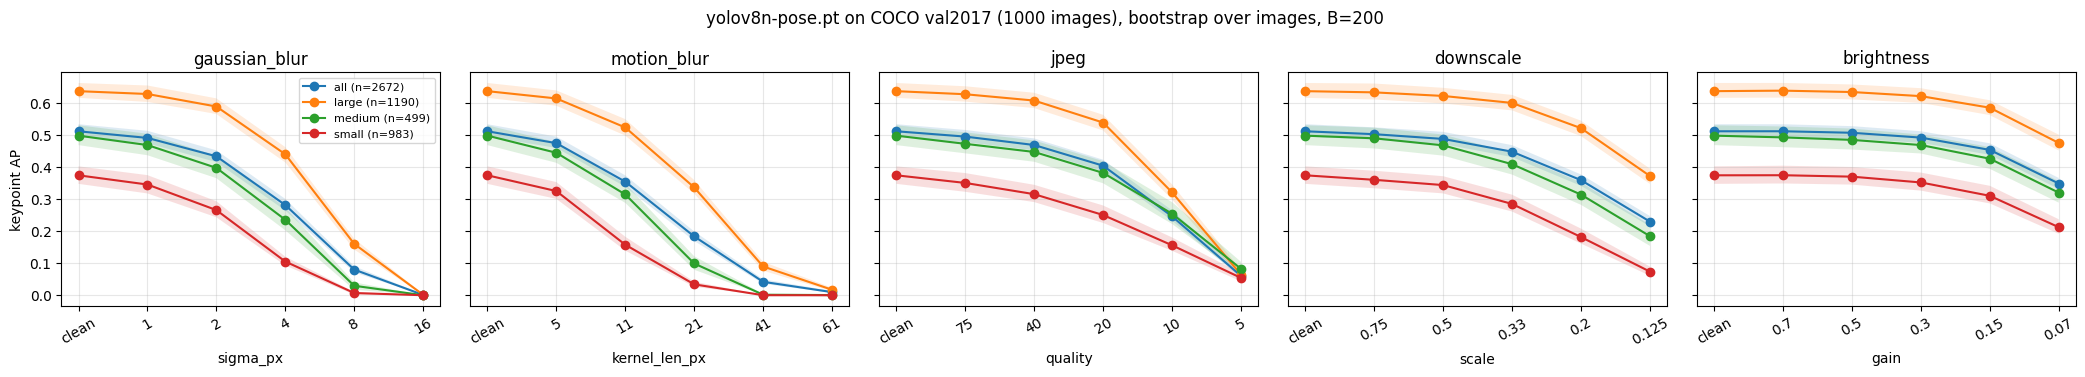

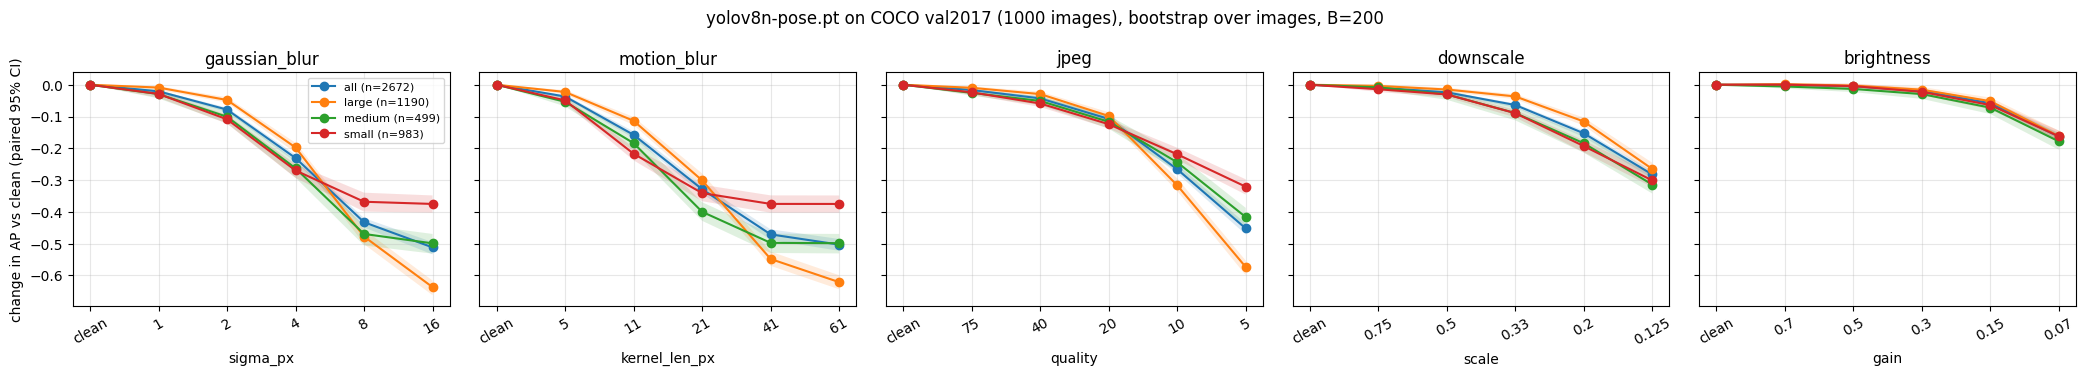

In [8]:
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
for m in MODELS:
    for value, lo, hi, ylab, fname in (("AP", "AP_lo", "AP_hi", "keypoint AP", "ap"),
                                       ("dAP", "dAP_lo", "dAP_hi", "change in AP vs clean (paired 95% CI)", "dap")):
        fig, axes = plt.subplots(1, len(CORRUPTIONS), figsize=(4.2 * len(CORRUPTIONS), 3.8), sharey=True)
        for ax, (cname, (pname, params, _)) in zip(axes, CORRUPTIONS.items()):
            for s in STRATA_TO_PLOT:
                d = results[(results.model == m) & (results.corruption == cname) & (results.stratum == s)].sort_values("level")
                ax.plot(d.level, d[value], marker="o", label=f"{s} (n={int(d.n_gt.iloc[0])})")
                ax.fill_between(d.level, d[lo], d[hi], alpha=0.15)
            ax.set_xticks(range(6)); ax.set_xticklabels(["clean"] + [str(p) for p in params], rotation=30)
            ax.set_xlabel(pname); ax.set_title(cname); ax.grid(True, alpha=0.3)
        axes[0].set_ylabel(ylab); axes[0].legend(fontsize=8)
        fig.suptitle(f"{m} on COCO val2017 ({len(img_ids)} images), bootstrap over images, B={B}")
        plt.tight_layout(); plt.savefig(f"figures/{fname}_{m.replace('.pt', '')}.png", dpi=200); plt.show()

# Step 8: Qualitative examples (for the README)

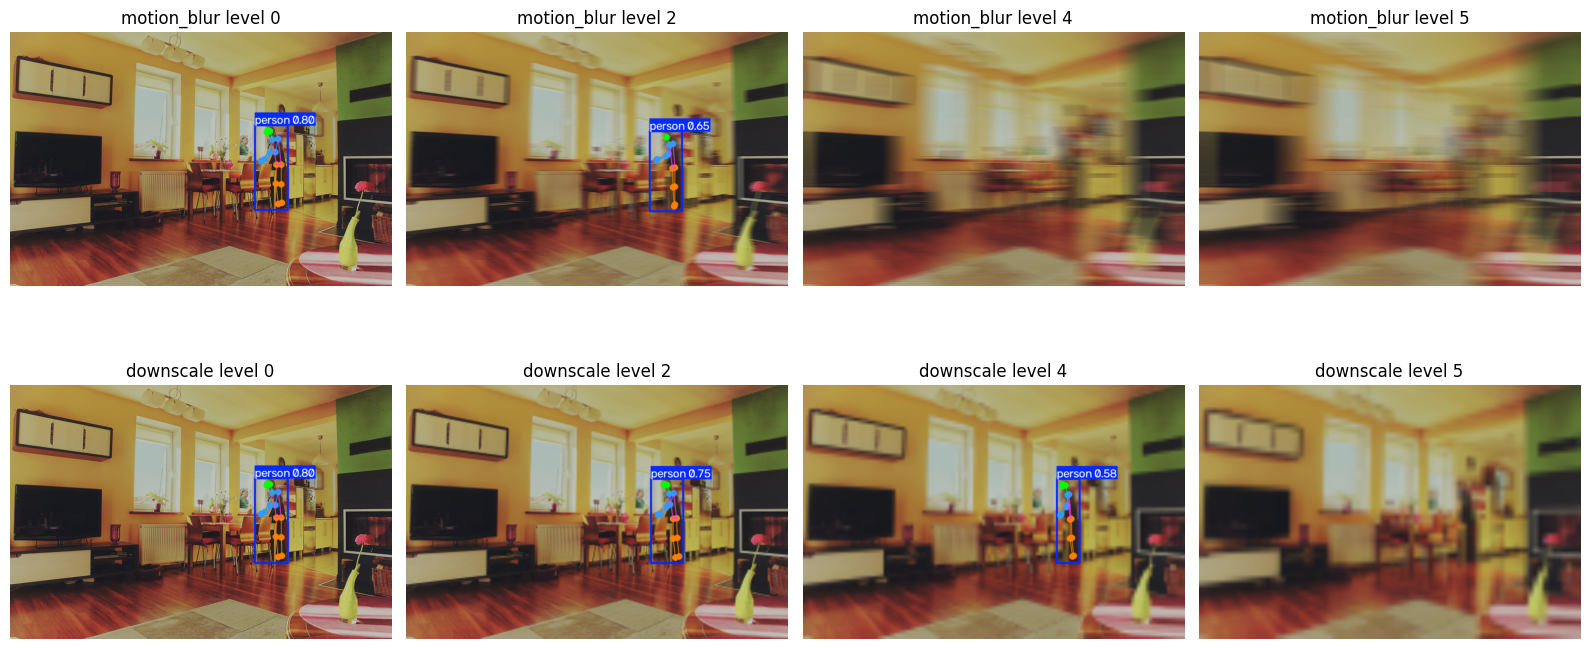

In [9]:
m = MODELS[0]; model = YOLO(m)
k = 0
shows = [("motion_blur", [0, 2, 4, 5]), ("downscale", [0, 2, 4, 5])]
fig, axes = plt.subplots(len(shows), 4, figsize=(16, 4 * len(shows)))
for r, (cname, lvls) in enumerate(shows):
    for ccol, lvl in enumerate(lvls):
        im = apply_corruption(images[k], cname, lvl)
        out = model.predict(im, imgsz=640, conf=0.25, max_det=20, verbose=False)[0].plot()
        axes[r, ccol].imshow(out[:, :, ::-1]); axes[r, ccol].axis("off")
        axes[r, ccol].set_title(f"{cname} level {lvl}")
plt.tight_layout(); plt.savefig("figures/qualitative.png", dpi=150); plt.show()